# Image Classification 

This notebook explores Image Classification as a Linear Classifier, Neural Network, and then a Convolutional Neural Network (CNN).
Each step adds **one** new idea on top of the previous one:

| Part | Model | New idea |
| --- | --- | --- |
| 0 | — | An image is just a grid of numbers |
| 1 | Linear classifier (SVM) | $\text{score} = w^Tx + w_0$ on the raw (or hand-filtered) pixels |
| 2 | Neural network | Stack linear layers with an activation (ReLU) in between |
| 3 | — | What a **convolution** is: a small moving dot product |
| 4 | Convolutional neural network | Let the network **learn** its own convolution kernels |

## Dataset

The dataset is a bunch of pictures of flowers, labelled by type

### Example 
| File | 0001.png                                          | 0003.png                                          | 0006.png                                          | 0206.png                                          | 0207.png                                          | 0209.png                                          |
| ----- | ------------------------------------------------- | ------------------------------------------------- | ------------------------------------------------- | ------------------------------------------------- | ------------------------------------------------- | ------------------------------------------------- |
| Label | 0                                                 | 2                                                 | 1                                                 | 6                                                 | 0                                                 | 6                                                 |
| Image | ![flower_images/0001.png](flower_images/0001.png) | ![flower_images/0001.png](flower_images/0003.png) | ![flower_images/0001.png](flower_images/0006.png) | ![flower_images/0001.png](flower_images/0206.png) | ![flower_images/0001.png](flower_images/0207.png) | ![flower_images/0001.png](flower_images/0209.png) |

### Labels
Check [flower_images/flower_labels.csv](flower_images/flower_labels.csv)

| Label | 0  | 1  | 2  | 3  | 4  | 5  | 6  | 7  | 8  | 9  | **Total** |
| ----- | -- | -- | -- | -- | -- | -- | -- | -- | -- | -- | --------- |
| Count | 21 | 20 | 19 | 22 | 20 | 25 | 23 | 15 | 26 | 18 | **209**   |

> Only **209** images for 10 classes is a *tiny* dataset. Expect accuracies to jump around between runs,
> and expect models to overfit (memorize the training images) easily.

In [1]:
# ~ uncomment to install
# %pip install Pillow pandas scikit-learn matplotlib keras tensorflow

---
# Part 0 — An image is a grid of numbers

## Image to Feature Vector

The code uses PIL - Python Imaging Library [Pillow](https://pillow.readthedocs.io/en/stable/) to give you insights on how convolutions are applied on images.

[**Popular convolutions in image processing**](<https://en.wikipedia.org/wiki/Kernel_(image_processing)>)

Here we just load an image, and apply filters or matrix convolutions on top of an image.

Display Original Image
Channel:  RGBA
Width, Height:  (128, 128)


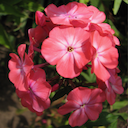

Image as an array, shape (height, width, channels): (128, 128, 4)
Top-left 3x3 pixels:
[[[ 13  22  10 255]
  [ 14  23   9 255]
  [ 16  24  10 255]]

 [[ 15  21  10 255]
  [ 14  23   9 255]
  [ 17  25  11 255]]

 [[ 16  24  10 255]
  [ 17  25  11 255]
  [ 17  25  12 255]]]


In [2]:
from PIL import Image
from PIL import ImageFilter
import numpy as np
import matplotlib.pyplot as plt

# open the image file and convert to matrix

img = Image.open("flower_images/0001.png")
print("Display Original Image")
print("Channel: ", img.mode)
print("Width, Height: ", img.size)
display(img)


# Height, Width, Channel as an array
img_array = np.array(img)
print("Image as an array, shape (height, width, channels):", img_array.shape)

# the full array is 128 x 128 x 4 numbers, so only print the top-left 3x3 pixels
# each pixel is [Red, Green, Blue, Alpha], every value is between 0 and 255
print("Top-left 3x3 pixels:")
print(img_array[:3, :3])

### Convert Image to Grey Scale

Notice the array difference when working with an RGBA image vs Grey Scale: each pixel goes from **4 numbers** (R, G, B, A) to **1 number** (brightness).
In CNN language, the colour image has **4 channels** and the grey image has **1 channel**.

Gray Scale Image
Channel:  L
Width, Height:  (128, 128)


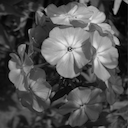

Image as an array, shape: (128, 128)
Top-left 5x5 pixels:
[[18 19 20 20 20]
 [18 19 21 23 23]
 [20 21 21 21 23]
 [23 30 30 23 23]
 [46 52 45 30 26]]


In [3]:
# Convert to Grey Scale
img2 = img.convert("L")

print("Gray Scale Image")
# Channel
print("Channel: ", img2.mode)
# Width, Height
print("Width, Height: ", img2.size)
display(img2)

img_array = np.array(img2)  # Height, Width  (only 1 channel, so no 3rd dimension)
print("Image as an array, shape:", img_array.shape)
print("Top-left 5x5 pixels:")
print(img_array[:5, :5])

### Applying FIND_EDGES filter (convolution) on the image.

`FIND_EDGES` slides a small 3x3 grid of numbers (a **kernel**) over the image. We'll see exactly how in Part 3.

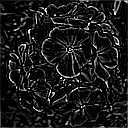

In [4]:
img3 = img2.filter(ImageFilter.FIND_EDGES)
display(img3)

### Applying a Custom Convolution on an image.

This is the same edge kernel, written out by hand:

$$
\begin{bmatrix} -1 & -1 & -1 \\ -1 & 8 & -1 \\ -1 & -1 & -1 \end{bmatrix}
$$

In a flat area all 9 pixels are about the same, so $8 \times \text{centre} - (\text{8 neighbours}) \approx 0$ (black).
At an edge the centre is different from its neighbours, so the result is large (bright).

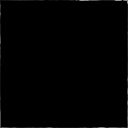

In [5]:
img3 = img2.filter(ImageFilter.Kernel((3, 3), (-1, -1, -1, -1, 8, -1, -1, -1, -1)))
display(img3)

### A quick helper function to show an image as a vector shape

A linear classifier needs **one long vector** per example, so we `flatten` the 2D (or 3D) grid into a 1D list.

In [6]:
def img2vec(f_name, flatten=False):
    # Helper function to display an image as a vector
    img = Image.open(f_name)
    img_array = np.array(img)
    if flatten:
        return img_array.flatten()
    else:
        return img_array


fname = "flower_images/0001.png"
a = img2vec(fname)
print("Image Array Dimensions ", a.shape)

v = img2vec(fname, flatten=True)
print("Flattened Dimensions   ", v.shape, " <- 128 * 128 * 4 =", 128 * 128 * 4)
print("First 12 values (3 pixels x RGBA):", v[:12])

Image Array Dimensions  (128, 128, 4)
Flattened Dimensions    (65536,)  <- 128 * 128 * 4 = 65536
First 12 values (3 pixels x RGBA): [ 13  22  10 255  14  23   9 255  16  24  10 255]


---
# Part 1 — Linear Image Classification using `scikit`

Each image becomes a vector $x$ (all its pixels), and a linear classifier computes a score
$w^Tx + w_0$ — exactly like the 2-feature examples in the linear-classifier notebooks, just with
**16,384 features** (128 x 128 grey pixels) instead of 2.

With 10 classes, scikit uses **one-vs-rest**: it trains 10 separate linear classifiers ("is it class 0 or not?",
"is it class 1 or not?", ...) and predicts the class with the highest score.

In this example we are going to apply pre-existing filters or fixed convolutions on the image, and use that the train a linear classifier

Support vector machines (SVMs) are a set of supervised learning methods used for classification, regression and outliers detection.

[**SVM Classification**](https://scikit-learn.org/stable/modules/svm.html#svm-classification)

Try a set of combinations with image type (RBGA vs L) and with and without fixed convolutions to train a model, you can see how each of them behave, and if that affects the accuracy of results

> **cross_val_score(cv=5)** splits the 209 images into 5 parts, trains on 4 and tests on the 5th, 5 times.
> The average of the 5 scores is a fairer estimate than a single train/test split.

In [7]:
from sklearn import svm
from sklearn.model_selection import cross_val_score

# open the flowers...
f = open("flower_images/flower_labels.csv")
names = f.readlines()

data = []
labels = []

### 1. Train Data with fixed convolutions

Take a model with fixed convolutions and see the accuracy of score

Every image is passed through **9 hand-picked filters**. Each filtered image is flattened and the 9 vectors are joined together,
so each example has $9 \times 16{,}384 = 147{,}456$ features. Here **we** chose the kernels — in Part 4 the CNN will learn them.

In [8]:
for i in range(1, len(names), 1):
    names[i] = names[i].strip("\n")
    l = names[i].split(",")
    labels.append(int(l[1]))
    img = Image.open("flower_images/" + l[0])
    img = img.convert("L")
    img1 = np.array(img.filter(ImageFilter.FIND_EDGES)).flatten()
    img2 = np.array(img.filter(ImageFilter.DETAIL)).flatten()
    img3 = np.array(img.filter(ImageFilter.CONTOUR)).flatten()
    img4 = np.array(img.filter(ImageFilter.SHARPEN)).flatten()
    img5 = np.array(img.filter(ImageFilter.EDGE_ENHANCE)).flatten()
    img6 = np.array(img.filter(ImageFilter.EDGE_ENHANCE_MORE)).flatten()
    img7 = np.array(img.filter(ImageFilter.SMOOTH_MORE)).flatten()
    img8 = np.array(img.filter(ImageFilter.BLUR)).flatten()
    img9 = np.array(img.filter(ImageFilter.EMBOSS)).flatten()
    data.append(np.concatenate((img1, img2, img3, img4, img5, img6, img7, img8, img9)))

print(
    "Total Labels: ",
    len(labels),
    " | Total Data: ",
    len(data),
    " <-- make sure they match!",
)
print("sample: ", len(data[0]))

clf = svm.LinearSVC(max_iter=100, verbose=10)
scores = cross_val_score(clf, data, labels, cv=5)
print("scores: ", scores)
print("average score: ", sum(scores) / len(scores))

Total Labels:  209  | Total Data:  209  <-- make sure they match!
sample:  147456
[LibLinear]..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 129
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 105
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 128
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 122
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 54
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 133
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 106
..........
optimization fi

/Users/vmehta/Library/Mobile Documents/com~apple~CloudDocs/workspace/ds675/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 129
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 109
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 129
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 122
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 55
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 126
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 105
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV

/Users/vmehta/Library/Mobile Documents/com~apple~CloudDocs/workspace/ds675/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 135
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 106
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 132
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 123
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 55
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 112
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 111
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV

/Users/vmehta/Library/Mobile Documents/com~apple~CloudDocs/workspace/ds675/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


[LibLinear]..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 139
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 97
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 127
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 115
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 56
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 125
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 112
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.

/Users/vmehta/Library/Mobile Documents/com~apple~CloudDocs/workspace/ds675/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 133
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 93
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 120
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 124
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 50
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 129
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV = 122
..........
optimization finished, #iter = 100

Using -s 2 may be faster (also see FAQ)

Objective value = -0.000000
nSV 

/Users/vmehta/Library/Mobile Documents/com~apple~CloudDocs/workspace/ds675/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


### 2. Train Data with raw pixels (no convolutions)

Same model, but now each example is just the 16,384 grey pixel values — no filters at all.

In [9]:
data = []
labels = []
for i in range(1, len(names), 1):
    names[i] = names[i].strip("\n")
    l = names[i].split(",")
    labels.append(int(l[1]))
    img = Image.open("flower_images/" + l[0])
    img = img.convert("L")
    img_array = np.array(img)
    data.append(img_array.flatten())

print(
    "Total Labels: ",
    len(labels),
    " | Total Data: ",
    len(data),
    " <-- make sure they match!",
)

print("sample: ", len(data[0]))

Total Labels:  209  | Total Data:  209  <-- make sure they match!
sample:  16384


#### Running LinearSVC

[LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html)

> Similar to SVC with parameter kernel=’linear’, but implemented in terms of liblinear rather than libsvm, so it has more flexibility in the choice of penalties and loss functions and should scale better to large numbers of samples.
>
> The main differences between LinearSVC and SVC lie in the loss function used by default, and in the handling of intercept regularization between those two implementations.

Regularized along with weights, with multi-class classification of one vs the rest

`loss="hinge"` is the same hinge loss $\max(0, 1 - y_i(w^Tx_i + w_0))$ from the linear-classifier notebook, plus $L_2$ regularization on $w$.

Try different `loss` functions, and play around with `max_iter` to check the change in results

In [10]:
clf = svm.LinearSVC(max_iter=10000, loss="hinge", verbose=10)
scores = cross_val_score(clf, data, labels, cv=5)
print("scores: ", scores)
print("average score: ", sum(scores) / len(scores))

[LibLinear]..........................**
optimization finished, #iter = 267
Objective value = -0.000002
nSV = 108
..............................*.****
optimization finished, #iter = 319
Objective value = -0.000001
nSV = 81
.................................**
optimization finished, #iter = 338
Objective value = -0.000002
nSV = 98
..........................*
optimization finished, #iter = 269
Objective value = -0.000002
nSV = 98
............*
optimization finished, #iter = 122
Objective value = -0.000000
nSV = 40
.......................................*............***
optimization finished, #iter = 519
Objective value = -0.000002
nSV = 113
.....................**
optimization finished, #iter = 216
Objective value = -0.000001
nSV = 81
.................................**.*
optimization finished, #iter = 342
Objective value = -0.000001
nSV = 79
...........................*..........**
optimization finished, #iter = 379
Objective value = -0.000001
nSV = 103
............................***.
op

#### Running SVC with a linear kernel

Another `kernel` for SVC — the plain linear one, for comparison with `LinearSVC` above.

In [11]:
clf = svm.SVC(kernel="linear", verbose=True)
scores = cross_val_score(clf, data, labels, cv=5)
print("scores: ", scores)
print("average score: ", sum(scores) / len(scores))

[LibSVM].*.*
optimization finished, #iter = 75
obj = -0.000000, rho = 1.543217
nSV = 26, nBSV = 0
.*.*
optimization finished, #iter = 90
obj = -0.000001, rho = 2.897846
nSV = 32, nBSV = 0
.*.*
optimization finished, #iter = 92
obj = -0.000001, rho = -2.520357
nSV = 30, nBSV = 0
.*.*
optimization finished, #iter = 72
obj = -0.000000, rho = 0.279121
nSV = 24, nBSV = 0
...*.*
optimization finished, #iter = 149
obj = -0.000001, rho = -2.741604
nSV = 36, nBSV = 0
..*.*
optimization finished, #iter = 103
obj = -0.000000, rho = 0.578965
nSV = 30, nBSV = 0
..*.*
optimization finished, #iter = 107
obj = -0.000000, rho = 0.007727
nSV = 28, nBSV = 0
..*
optimization finished, #iter = 104
obj = -0.000001, rho = 0.284272
nSV = 35, nBSV = 0
.*.*
optimization finished, #iter = 79
obj = -0.000000, rho = -1.526532
nSV = 28, nBSV = 0
.*.*
optimization finished, #iter = 67
obj = -0.000000, rho = 0.901652
nSV = 28, nBSV = 0
.*.*
optimization finished, #iter = 82
obj = -0.000000, rho = -3.041720
nSV = 32, 

#### Finding the best regularization value $C$

$C$ controls the trade-off between hinge loss and regularization (large $C$ = less regularization).
`get_best_C` in [svm_cross_validate.py](svm_cross_validate.py) tries $C \in \{0.001, 0.01, 0.1, 1, 10, 100\}$ on 10 random 90/10 splits and returns the one with the lowest average validation error.

> This can take up to a minute or two, depending upon your laptop

In [ ]:
import svm_cross_validate

best_C, min_error = svm_cross_validate.get_best_C(data, labels)
print("best C:", best_C, "| validation error:", min_error)

ModuleNotFoundError: No module named 'svm_cross_validate'

### Where linear classifiers struggle with images

* A linear classifier gives **one weight per pixel**. It can only learn "pixel (40, 60) being bright is evidence for class 3".
  If the flower moves a few pixels to the left, completely different weights are used.
* It cannot combine features: "a red patch *next to* a green stem" is not a single weighted sum of pixels.
* Using hand-picked filters (section 1) helps, but **we** had to guess which filters are useful.

The next two parts fix these one at a time: neural networks combine features, and CNNs learn filters that slide over the image.

---
# Part 2 — From Linear Classifier to Neural Network (Keras)

We switch from `scikit` to `keras`, which lets us build models layer by layer. To keep the comparison fair, all models in Part 2 and Part 4 use:

* the same images, resized to **32 x 32** with 3 colour channels (R, G, B — the alpha channel is dropped). Smaller images mean fewer weights and faster training.
* the same split: first **177** images for training, last **32** for testing.

### Load and prepare the data

In [ ]:
import keras
import pandas as pd
import tensorflow as tf
from keras.layers import Dense, Dropout, Activation, Flatten
from keras.layers import Conv2D, MaxPool2D, AveragePooling2D
from keras.models import Sequential

keras.utils.set_random_seed(42)  # so re-running gives (almost) the same results

num_classes = 10
epochs = 100
batch_size = 4

img_rows, img_cols = 32, 32

df = pd.read_csv("flower_images/flower_labels.csv")  # load images' names and labels
names = df["file"].values
labels = df["label"].values.reshape(-1, 1)

print("names: ", len(names))
print("labels: ", len(labels))

data = []

for name in names:
    img = Image.open("flower_images/" + name)  # shape is 128x128x4
    img = img.resize((img_rows, img_cols))  # resize image into fixed size 32x32x4
    img = np.array(img)[np.newaxis, :, :, :3]  # keep R,G,B only and add a new axis -> 1x32x32x3
    data.append(img)

data = np.concatenate(data)  # stack all images, shape is 209x32x32x3

print("data loaded: ", data.shape)

names:  209
labels:  209
data loaded:  (209, 32, 32, 3)


* Pixel values are scaled from $[0, 255]$ to $[0, 1]$ — like normalizing features for linear classification, this makes one learning rate work well for all weights.
* Labels become **one-hot** vectors: label `3` → `[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]`. The model outputs 10 scores, one per class.

In [ ]:
x_train = data[:177].astype(np.float32)
y_train = labels[:177]
x_test = data[177:].astype(np.float32)  # set the last 32 images as test dataset
y_test = labels[177:]
x_train /= 255
x_test /= 255

# convert label into one-hot vector
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

print("x_train:", x_train.shape, "| y_train:", y_train.shape)
print("x_test: ", x_test.shape, " | y_test: ", y_test.shape)
print("label of first image as one-hot:", y_train[0])

x_train: (177, 32, 32, 3) | y_train: (177, 10)
x_test:  (32, 32, 32, 3)  | y_test:  (32, 10)
label of first image as one-hot: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


### Helpers: train a model and plot its learning curves

We pass the test set as `validation_data` only so Keras reports test accuracy after every epoch — it is **never** used to update the weights.

* **training accuracy** going up while **test accuracy** stays flat = the model is memorizing (overfitting).

In [ ]:
results = {}  # model name -> final test accuracy, for the comparison at the end


def train(model, name, epochs=epochs, callbacks=None):
    history = model.fit(
        x_train,
        y_train,
        batch_size=batch_size,
        epochs=epochs,
        validation_data=(x_test, y_test),
        shuffle=True,
        callbacks=callbacks,
        verbose=0,  # change to 1 to watch every epoch
    )
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
    results[name] = accuracy
    print(f"{name}: trained {len(history.history['loss'])} epochs | "
          f"train accuracy {history.history['accuracy'][-1]:.3f} | test accuracy {accuracy:.3f}")
    plot_history(history, name)
    return history


def plot_history(history, title):
    fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(12, 3.5))
    ax_acc.plot(history.history["accuracy"], label="train")
    ax_acc.plot(history.history["val_accuracy"], label="test")
    ax_acc.set_title("accuracy")
    ax_acc.set_ylim(0, 1.05)
    ax_loss.plot(history.history["loss"], label="train")
    ax_loss.plot(history.history["val_loss"], label="test")
    ax_loss.set_title("loss")
    for ax in (ax_acc, ax_loss):
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

### 2a. A linear classifier, written in Keras

Before adding anything new, let's rebuild a **linear classifier** in Keras so we know exactly what changes in the next step.

* `Flatten()` turns the $32 \times 32 \times 3$ image into a vector of $3072$ numbers — same as `img.flatten()` in Part 1.
* `Dense(10)` computes 10 scores, one per class: $\text{score}_c = w_c^Tx + w_{0,c}$. That is $3072 \times 10$ weights $+ 10$ biases.
* `loss="categorical_hinge"` is the multi-class version of hinge loss: it wants the correct class's score to beat the best wrong score by at least 1.
* `kernel_regularizer=l2(...)` adds $\lambda \lVert w \rVert^2$ — the same $L_2$ regularization as before.

So this is a linear classifier with hinge loss and regularization, trained by gradient descent — nothing new yet.

In [ ]:
linear_model = Sequential([
    keras.Input(shape=(32, 32, 3)),
    Flatten(),
    Dense(num_classes, kernel_regularizer=keras.regularizers.l2(0.001)),  # 10 linear scores
])
linear_model.compile(loss="categorical_hinge", optimizer=keras.optimizers.SGD(learning_rate=0.01), metrics=["accuracy"])
linear_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        30,730 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,730 (120.04 KB)

 Trainable params: 30,730 (120.04 KB)

 Non-trainable params: 0 (0.00 B)

Linear classifier (hinge): trained 100 epochs | train accuracy 1.000 | test accuracy 0.344


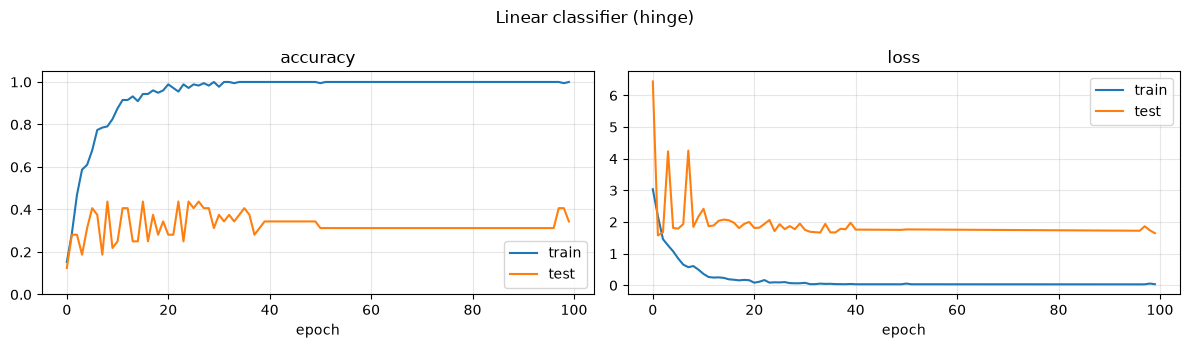

In [ ]:
train(linear_model, "Linear classifier (hinge)");

### 2b. Neural network: add a hidden layer

A neural network stacks linear layers with an **activation function** in between:

$$
h = \text{relu}(W_1 x + b_1) \qquad \text{scores} = W_2 h + b_2
$$

* $\text{relu}(z) = \max(0, z)$ — notice it has the same "corner at zero" shape as the hinge.
* Without the activation, two linear layers collapse into one linear layer ($W_2 W_1 x$ is still linear). The activation is what lets the network combine features in non-linear ways.
* Each of the 128 hidden units is its own linear classifier on the pixels; the output layer is a linear classifier on those 128 results.

Two standard changes for multi-class networks:

* **softmax** turns the 10 scores into probabilities that add up to 1: $p_c = \dfrac{e^{\text{score}_c}}{\sum_j e^{\text{score}_j}}$
* **categorical cross-entropy** loss $= -\log p_{\text{correct class}}$: small when the model gives the correct class a high probability. It plays the same role as hinge loss, but is smooth everywhere.

In [ ]:
nn_model = Sequential([
    keras.Input(shape=(32, 32, 3)),
    Flatten(),
    Dense(128, activation="relu"),  # hidden layer: 128 linear units + relu
    Dense(num_classes, activation="softmax"),  # output layer: 10 class probabilities
])
nn_model.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.Adam(learning_rate=0.001), metrics=["accuracy"])
nn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 394,634 (1.51 MB)

 Trainable params: 394,634 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

Neural network (1 hidden layer): trained 100 epochs | train accuracy 1.000 | test accuracy 0.344


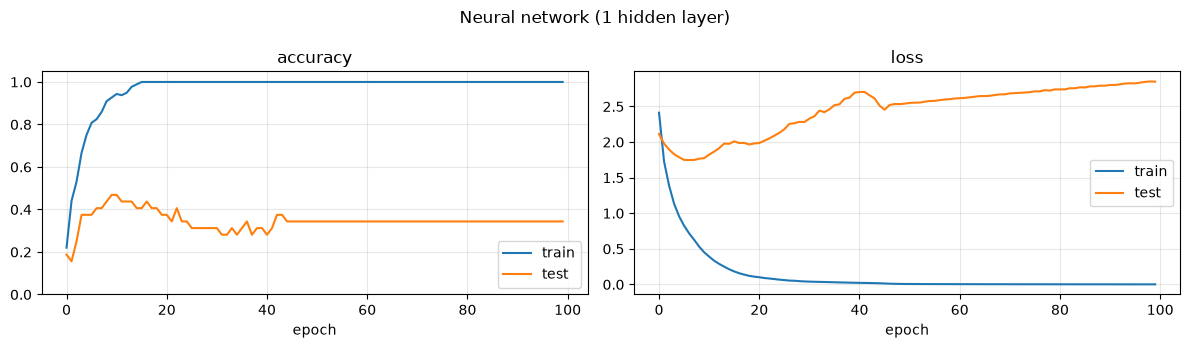

In [ ]:
train(nn_model, "Neural network (1 hidden layer)");

**Look at the parameter count** in the summary: almost all of the ~400k weights are in the first `Dense` layer ($3072 \times 128$).
Every hidden unit is connected to every pixel, and it still has no idea that neighbouring pixels belong together.
Convolutions fix this: a small kernel looks at a small neighbourhood, and the **same** kernel is reused at every position.

---
# Part 3 — Convolutional Neural Networks

### 3a. CNN with one convolution layer

The smallest possible CNN:

| Layer | Output shape | What it does |
| --- | --- | --- |
| input | 32 x 32 x 3 | RGB image |
| `Conv2D(32, 3x3, valid, relu)` | 30 x 30 x 32 | 32 learned 3x3x3 kernels, $(32-3)/1+1 = 30$ |
| `MaxPool2D(30x30)` | 1 x 1 x 32 | keep the **strongest** response of each kernel anywhere in the image |
| `Flatten` | 32 | one number per kernel: "how much of pattern $j$ is in this image" |
| `Dense(10)` + softmax | 10 | linear classifier on those 32 numbers |

So it's a linear classifier on top of 32 learned filters — compare with the 9 hand-picked PIL filters in Part 1.

In [ ]:
# generate model
model = Sequential()

model.add(
    Conv2D(filters=32, kernel_size=(3, 3), padding="valid", activation="relu", input_shape=[32, 32, 3])
)  # Convolution: 32 x 32 x 3 -> 30 x 30 x 32
model.add(MaxPool2D(pool_size=(30, 30)))  # 30x30 max pooling -> 1 x 1 x 32

model.add(Flatten())  # shape equals to [batch_size, 32] 32 is the number of filters
model.add(Dense(10))  # Fully connected layer
model.add(Activation("softmax"))

# lr=0.01, decay=1e-6
opt = keras.optimizers.RMSprop(learning_rate=0.01, weight_decay=1e-6)

model.compile(loss="categorical_crossentropy", optimizer=opt, metrics=["accuracy"])
model.summary()

/Users/vmehta/Library/Mobile Documents/com~apple~CloudDocs/workspace/ds675/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 1, 1, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,226 (4.79 KB)

 Trainable params: 1,226 (4.79 KB)

 Non-trainable params: 0 (0.00 B)

Check the parameter counts in the summary: `conv2d` has $3 \times 3 \times 3 \times 32 + 32 = 896$ and `dense` has $32 \times 10 + 10 = 330$.
The whole model has fewer weights than a single row of the Part 2 network's first layer.

CNN (1 conv layer): trained 100 epochs | train accuracy 0.904 | test accuracy 0.531


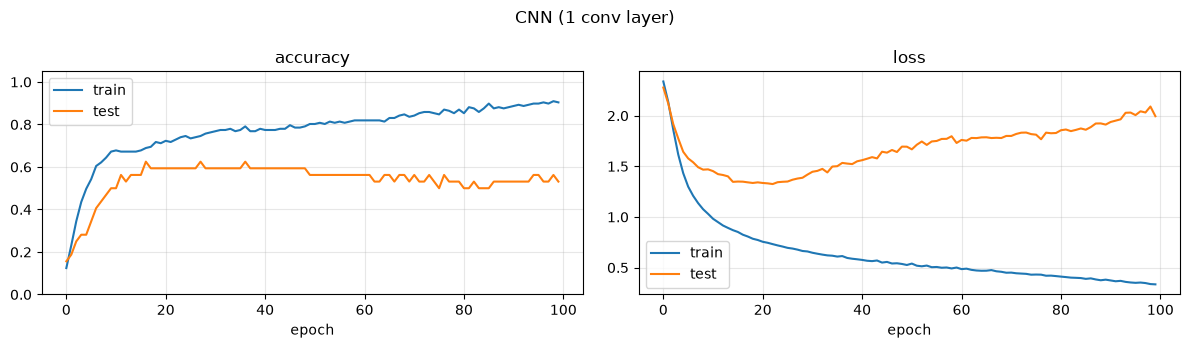

In [ ]:
train(model, "CNN (1 conv layer)");

### 3b. A deeper CNN, using the design & training notes

From [Training and designing convolutional neural networks](https://web.njit.edu/~usman/courses/ds675/Training%20and%20designing%20convolutional%20neural%20networks.pdf):

**Design**

* **Kernel size:** 3 (or 5) works well for most datasets; bigger kernels are slower and use more memory.
* **Number of kernels:** start with **32** in the first layer and **double** it in later layers (32 → 64).
* **Activation:** sigmoid $\frac{1}{1+e^{-x}}$ or relu $\max(0, x)$; relu often trains faster, accuracy is similar.
* **Image resize:** smaller images (we use 32x32) need fewer parameters and are easier to optimize.

**Training**

* **Learning rate:** start medium and decrease it every few epochs. Simple method: **divide by 2 every 10 epochs** (done below with `LearningRateScheduler`).
  Momentum, Adagrad, RMSprop and Adam adjust the step size automatically and help escape saddle points.
* **Early stopping:** with SGD there is no convergence test, so we choose when to stop. Simple rule from the notes: stop once **training accuracy reaches 100%** — the model can't fit the training data any better.
* **Data shuffling:** the order of examples and which ones land in each mini-batch affect training, so we shuffle every epoch (`shuffle=True`).
* **Batch normalization** (not used here — try adding `keras.layers.BatchNormalization()` after a `Conv2D`): normalizes values between layers, like normalizing features for a linear classifier.
* **Vanishing gradients:** in deep networks gradients get multiplied layer after layer and can shrink to 0; relu helps.

Architecture (similar to [flower_deep_network.py](flower_deep_network.py) and [cifar10_cnn.py](cifar10_cnn.py), made smaller for 177 training images):

| Layer | Output shape |
| --- | --- |
| input | 32 x 32 x 3 |
| `Conv2D(32, 3x3, same, relu)` | 32 x 32 x 32 |
| `MaxPool2D(2x2)` | 16 x 16 x 32 |
| `Conv2D(64, 3x3, same, relu)` | 16 x 16 x 64 |
| `MaxPool2D(2x2)` | 8 x 8 x 64 |
| `Flatten` | 4096 |
| `Dropout(0.5)` | 4096 — randomly zero half the values during training, a form of regularization |
| `Dense(10)` + softmax | 10 |

In [ ]:
deep_cnn = Sequential([
    keras.Input(shape=(32, 32, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPool2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),  # double the kernels in the next layer
    MaxPool2D(pool_size=(2, 2)),
    Flatten(),
    Dropout(0.5),
    Dense(num_classes, activation="softmax"),
])
deep_cnn.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.Adam(learning_rate=0.001), metrics=["accuracy"])
deep_cnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │        40,970 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,362 (235.79 KB)

 Trainable params: 60,362 (235.79 KB)

 Non-trainable params: 0 (0.00 B)

**Callbacks** are small functions Keras calls during training:

* `halve_every_10_epochs` — the learning-rate rule from the notes: $\eta = \eta_{\text{start}} \times 0.5^{\lfloor \text{epoch} / 10 \rfloor}$
* `StopAtFullTrainingAccuracy` — the early-stopping rule from the notes

training accuracy reached 100% at epoch 22, stopping
Deeper CNN (2 conv layers): trained 22 epochs | train accuracy 1.000 | test accuracy 0.562


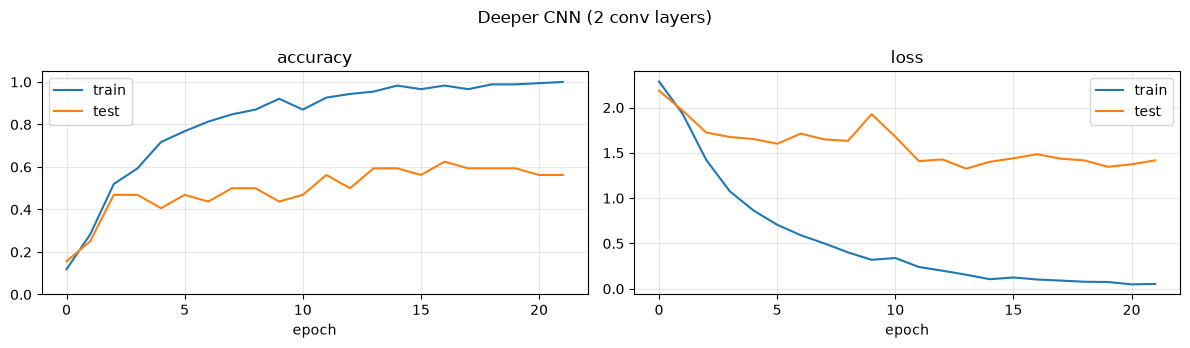

In [ ]:
start_lr = 0.001


def halve_every_10_epochs(epoch, lr):
    return start_lr * (0.5 ** (epoch // 10))


class StopAtFullTrainingAccuracy(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if logs["accuracy"] >= 1.0:
            print(f"training accuracy reached 100% at epoch {epoch + 1}, stopping")
            self.model.stop_training = True


callbacks = [
    keras.callbacks.LearningRateScheduler(halve_every_10_epochs),
    StopAtFullTrainingAccuracy(),
]

train(deep_cnn, "Deeper CNN (2 conv layers)", epochs=60, callbacks=callbacks);

---
## Comparing all the models

All Keras models were tested on the same 32 test images. Part 1 used 5-fold cross validation, so those numbers aren't directly comparable,
but they're in the same ballpark.

> With only 32 test images, one image = ~3% accuracy. Re-run with a different `set_random_seed` and the order of the bars may change — don't over-read small differences.

model                               | test accuracy
----------------------------------------------------
Linear classifier (hinge)           | 0.344
Neural network (1 hidden layer)     | 0.344
CNN (1 conv layer)                  | 0.531
Deeper CNN (2 conv layers)          | 0.562


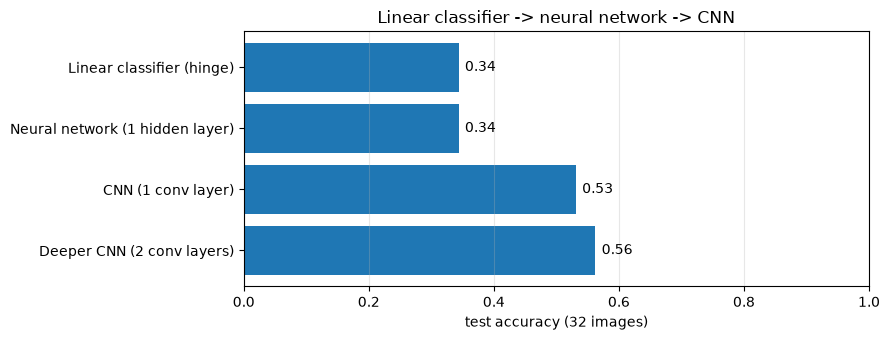

In [ ]:
print(f"{'model':35} | test accuracy")
print("-" * 52)
for name, acc in results.items():
    print(f"{name:35} | {acc:.3f}")

plt.figure(figsize=(9, 3.5))
plt.barh(list(results.keys()), list(results.values()), color="tab:blue")
for i, acc in enumerate(results.values()):
    plt.text(acc + 0.01, i, f"{acc:.2f}", va="center")
plt.xlim(0, 1)
plt.xlabel("test accuracy (32 images)")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.title("Linear classifier -> neural network -> CNN")
plt.tight_layout()
plt.show()

### Summary

1. **Linear classifier:** one weight per pixel. Works a bit, but can't handle a flower moving around in the image, and hand-picked filters are guesswork.
2. **Neural network:** hidden layers + relu let it combine features, but every unit is connected to every pixel — lots of weights and no idea of "neighbouring pixels".
3. **Convolution:** a small kernel, slid over the image as a moving dot product. Output size $\lfloor (n + 2p - k)/s \rfloor + 1$; one output channel per kernel; kernels have as many in-channels as the input.
4. **CNN:** the kernel values become weights learned by gradient descent, reused at every position, followed by pooling and a linear classifier on top.

**Try it yourself:**

* Change `img_rows, img_cols` to `64, 64` — does accuracy improve? How does the parameter count change?
* In the deeper CNN, change the kernel size to `(5, 5)` or the activation to `"sigmoid"`.
* Add `keras.layers.BatchNormalization()` after each `Conv2D`.
* Add `keras.layers.RandomFlip("horizontal")` right after `keras.Input(...)` — data augmentation like `horizontal_flip=True` in [cifar10_cnn.py](cifar10_cnn.py).
* Remove `Dropout(0.5)` — what happens to the gap between training and test accuracy?